# Python reading of particles

## Setup

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import numpy as np
import matplotlib.pyplot as pl
import sys
import os

*Set this to your DISPATCH top:*

In [4]:
top='c:/cygwin64/home/codes/dispatch2/'

Making sure to use the most current DISPATCH version:

In [5]:
sys.path.insert(0,top+'utilities/python')
cwd=top+'experiments/dust/ISM/python'
os.chdir(cwd)

In [41]:
import dispatch
import dispatch.particles

## Reading data from a ``1pc.nml`` input file run

In [287]:
p=dispatch.particles.open('../data/1pc/rank_00000.pdat',verbose=1);

18.87 Mp -> 1.96 Mp/s   199 snapshots 64350 particles


### Selecting particles with z in a narrow interval

In [288]:
w1=np.where(np.logical_and(p.t[:,1]>0.0,p.bin[:,1]==1))[0]
print('there are',len(w1),'actual particles')
z0=p.r[w1,2,0]
w2=np.where(abs(z0-0.5)< 0.001)[0]
print('there are',len(w2),'particles in the given z-interval')
w=w1[w2]

there are 21054 actual particles
there are 66 particles in the given z-interval


#### Plotting their starting points

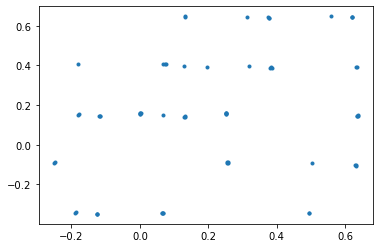

In [289]:
x0=p.r[w,0,0]
y0=p.r[w,1,0]
pl.plot(x0,y0,'.');

#### Plotting their parths in time

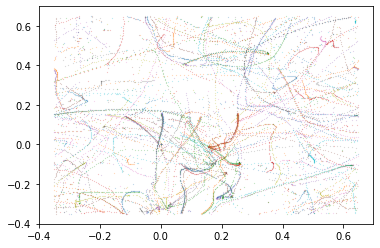

In [297]:
for i in range(len(w)):
    x=p.r[w[i],0,:]
    y=p.r[w[i],1,:]
    dx=x[1:]-x[:-1]
    dy=y[1:]-y[:-1]
    #if all(abs(dx)<0.1) and all(abs(dy)<0.1):
    pl.plot(x,y,'.',ms=0.2)